# Analisis exploratorio de la produccion de equipos

In [1]:
import sys 
import os
from pathlib import Path
import importlib
from prefect import task

import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from prophet import Prophet
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import matplotlib.dates as mdates

ROOT = Path().cwd().parents[1]
sys.path.append(str(ROOT))


import config.settings as settings
import importlib

import warnings
warnings.filterwarnings("ignore")

/home/jorge/Projects/Radioterapia/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


17:17:28.327 | ERROR   | prophet.plot - Importing plotly failed. Interactive plots will not work.

## Extraer la produccion por equipos 

In [2]:
df_produccion = pd.read_excel(ROOT / 'data' / 'raw' / 'SESIONES_RADIOTERAPIA_5MAY22-30ABR2026.xlsx',
                                      sheet_name = 0,
                                      engine = "openpyxl")
df_produccion.columns = df_produccion.columns.str.lower()

In [3]:
df_produccion.columns = ['ds','equipo','y','capacidad','tipo_dia','novedad']
df_produccion['weekend'] = np.where(df_produccion['tipo_dia'] == 'fin de semana',1,0)
df_produccion['novedad'] = df_produccion["novedad"].fillna("ninguna")
print(df_produccion.head(10))


          ds    equipo   y  capacidad tipo_dia  novedad  weekend
0 2022-05-03   HALCYON  59         70  laboral  ninguna        0
1 2022-05-03   SYNERGY  41         65  laboral  ninguna        0
2 2022-05-03  SYNERGY2  32         47  laboral  ninguna        0
3 2022-05-03  SYNERGY3  34         47  laboral  ninguna        0
4 2022-05-04   HALCYON  64         70  laboral  ninguna        0
5 2022-05-04   SYNERGY  45         65  laboral  ninguna        0
6 2022-05-04  SYNERGY2  37         47  laboral  ninguna        0
7 2022-05-04  SYNERGY3  34         47  laboral  ninguna        0
8 2022-05-05   HALCYON  63         70  laboral  ninguna        0
9 2022-05-05   SYNERGY  46         65  laboral  ninguna        0


In [4]:
list(df_produccion['equipo'].unique())

['HALCYON',
 'SYNERGY',
 'SYNERGY2',
 'SYNERGY3',
 'HALCYON3',
 'HALCYON4',
 'HALCYON5',
 'EDGE1_6107',
 'EDGE2_6137']

In [5]:
df_produccion.groupby('novedad')['equipo'].size()
df_produccion.to_csv(ROOT/'data'/'processed'/ 'produccion_x_equipo.csv',
                    index = False,
                    encoding = "utf-8")

In [6]:
df_output = df_produccion[df_produccion['equipo'] == "HALCYON" ].copy() 
print(type(df_output))

<class 'pandas.core.frame.DataFrame'>


In [7]:

summary = df_produccion.groupby('equipo').agg(
    size = ('equipo', 'size'),
    min_date = ('ds', 'min'),
    max_date = ('ds', 'max')
)

print(summary)

            size   min_date   max_date
equipo                                
EDGE1_6107   647 2024-07-23 2026-04-30
EDGE2_6137   646 2024-07-24 2026-04-30
HALCYON     1459 2022-05-03 2026-04-30
HALCYON3     954 2023-09-20 2026-04-30
HALCYON4     954 2023-09-20 2026-04-30
HALCYON5     954 2023-09-20 2026-04-30
SYNERGY      974 2022-05-03 2024-12-31
SYNERGY2    1351 2022-05-03 2026-01-12
SYNERGY3    1425 2022-05-03 2026-03-27


## Bottom up forecasting HALCYON

In [8]:
df = df_produccion[df_produccion['equipo']=="HALCYON"]
df['ds'] = pd.to_datetime(df['ds'])

split = int(len(df)*0.9)
print(split)
train = df.iloc[:split]
test_aux = df.iloc[(split+1):]
split1 = int(len(test_aux)*0.5)

validation = test_aux.iloc[:split1]
test = test_aux.iloc[(split1+1):]

ntrain = train.shape[0]
nvalidation = validation.shape[0]
ntest = test.shape[0]
print("--Training--")
print(f"Observations in training set: {ntrain}")
print(f"min date: {train['ds'].min()}")
print(f"max date: {train['ds'].max()}")

print("--Validation--")
print(f"Observations in validation set: {nvalidation}")
print(f"min date: {validation['ds'].min()}")
print(f"max date: {validation['ds'].max()}")

print("--Test--")
print(f"Observations in test set: {ntest}")
print(f"min date: {test['ds'].min()}")
print(f"max date: {test['ds'].max()}")



1313
--Training--
Observations in training set: 1313
min date: 2022-05-03 00:00:00
max date: 2025-12-05 00:00:00
--Validation--
Observations in validation set: 72
min date: 2025-12-07 00:00:00
max date: 2026-02-16 00:00:00
--Test--
Observations in test set: 72
min date: 2026-02-18 00:00:00
max date: 2026-04-30 00:00:00


In [9]:
df_series = df[['ds','y']]

In [10]:
print(train.columns)
print(f"train size  = {validation.shape[0]}")
print(train[['ds','y']])

Index(['ds', 'equipo', 'y', 'capacidad', 'tipo_dia', 'novedad', 'weekend'], dtype='object')
train size  = 72
             ds   y
0    2022-05-03  59
4    2022-05-04  64
8    2022-05-05  63
12   2022-05-06  55
16   2022-05-07   0
...         ...  ..
8300 2025-12-01  35
8307 2025-12-02  33
8316 2025-12-03  36
8324 2025-12-04  36
8332 2025-12-05  31

[1313 rows x 2 columns]


In [11]:
print(f"validation size  = {validation.shape[0]}")
print(validation[['ds','y']])

validation size  = 72
             ds   y
8348 2025-12-07   0
8356 2025-12-08  30
8364 2025-12-09  31
8372 2025-12-10  29
8380 2025-12-11  27
...         ...  ..
8854 2026-02-12  37
8861 2026-02-13  35
8868 2026-02-14   0
8875 2026-02-15   0
8882 2026-02-16   0

[72 rows x 2 columns]


In [12]:
print(test)


             ds   equipo   y  capacidad       tipo_dia  novedad  weekend
8896 2026-02-18  HALCYON  33         60        laboral  ninguna        0
8903 2026-02-19  HALCYON  34         60        laboral  ninguna        0
8910 2026-02-20  HALCYON  33         60        laboral  ninguna        0
8917 2026-02-21  HALCYON   0          0  fin de semana  ninguna        1
8924 2026-02-22  HALCYON   0          0  fin de semana  ninguna        1
...         ...      ...  ..        ...            ...      ...      ...
9336 2026-04-26  HALCYON   0          0  fin de semana  ninguna        1
9342 2026-04-27  HALCYON  39         55        laboral  ninguna        0
9348 2026-04-28  HALCYON  30         55        laboral  ninguna        0
9354 2026-04-29  HALCYON  38         55        laboral  ninguna        0
9360 2026-04-30  HALCYON   0          0        festivo  ninguna        0

[72 rows x 7 columns]


In [13]:
# Initialize and fit Prophet model
model = Prophet(
    # Seasonality settings
    yearly_seasonality=True, # Enable yearly patterns
    weekly_seasonality=True, # Enable weekly patterns
    daily_seasonality=False, # Disable daily (we have daily data but we want weekly patterns) 
    # Trend flexibility
    changepoint_prior_scale=0.05, # Lower = less flexible trend changes
    changepoint_range=0.8, # Proportion of data to consider for changepoints

    # Seasonality strength
    seasonality_prior_scale=10.0, # Higher = more flexible sasonality
    seasonality_mode='additive', # Additive seasonality (default)
    # Uncertainty intervals
    interval_width = 0.95, #95% confidence intervals
    mcmc_samples=0, # use MAP estimation (faster than MCMC)
)
model.fit(train)
future = model.make_future_dataframe(periods = nvalidation, freq = 'D')
forecast = model.predict(future)
cols = ['yhat', 'yhat_lower', 'yhat_upper']
forecast[cols] = forecast[cols].clip(lower = 0)


In [14]:
print(f"min date: {forecast['ds'].min()}")
print(f"max date: {forecast['ds'].max()}")

print("--Forecast--")
print(forecast.tail(5))

min date: 2022-05-03 00:00:00
max date: 2026-02-15 00:00:00
--Forecast--
             ds      trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
1380 2026-02-11  13.621017         0.0   48.195509    13.544249    13.693835   
1381 2026-02-12  13.596021         0.0   44.452862    13.517310    13.670663   
1382 2026-02-13  13.571025         0.0   41.759804    13.490371    13.647487   
1383 2026-02-14  13.546029         0.0    0.356586    13.463433    13.624038   
1384 2026-02-15  13.521033         0.0    0.000000    13.436494    13.600500   

      additive_terms  additive_terms_lower  additive_terms_upper     weekly  \
1380        9.590722              9.590722              9.590722  15.338482   
1381        7.698670              7.698670              7.698670  13.731010   
1382        2.879240              2.879240              2.879240   9.112812   
1383      -37.437059            -37.437059            -37.437059 -31.089484   
1384      -37.442328            -37.442328         

In [15]:
## Evaluating forecast


# Eval train and validation
size_forecast = forecast.shape[0]
forecast['ds'] = pd.to_datetime(forecast['ds'])
df['ds'] = pd.to_datetime(df['ds'])

eval_train_test = forecast[['ds','yhat']].merge(df[['ds','y']],
                                                     on = 'ds',how = 'left')


#eval_train_test = forecast[['ds','yhat']].merge(df[['ds','y']].iloc[:size_forecast],
#                                                     on = 'ds',how = 'inner')
print("--Train and Validation sets--")
print(f"min date: {eval_train_test['ds'].min()}")
print(f"max date: {eval_train_test['ds'].max()}")

print(eval_train_test.tail(5))


--Train and Validation sets--
min date: 2022-05-03 00:00:00
max date: 2026-02-15 00:00:00
             ds       yhat   y
1380 2026-02-11  23.211739  35
1381 2026-02-12  21.294690  37
1382 2026-02-13  16.450265  35
1383 2026-02-14   0.000000   0
1384 2026-02-15   0.000000   0


In [16]:
print("--Entire serie--")
print(f"min date {df['ds'].min()} ")  
print(f"mex date {df['ds'].max()} ")
print("-----------------")


print("--Forecast period--")
print(f"min date {forecast['ds'].min()} ")  
print(f"mex date {forecast['ds'].max()} ")
print("-----------------")

print("--Eval_train_test--")
print(f"min date {eval_train_test['ds'].min()} ")  
print(f"mex date {eval_train_test['ds'].max()} ")




--Entire serie--
min date 2022-05-03 00:00:00 
mex date 2026-04-30 00:00:00 
-----------------
--Forecast period--
min date 2022-05-03 00:00:00 
mex date 2026-02-15 00:00:00 
-----------------
--Eval_train_test--
min date 2022-05-03 00:00:00 
mex date 2026-02-15 00:00:00 


In [17]:
print(eval_train_test['yhat'])
print(eval_train_test['y'])
eval_train_test['se'] = (eval_train_test['yhat'] - eval_train_test['y']) ** 2 
print(eval_train_test)

0       58.206406
1       58.992769
2       57.121604
3       52.265790
4       11.853813
          ...    
1380    23.211739
1381    21.294690
1382    16.450265
1383     0.000000
1384     0.000000
Name: yhat, Length: 1385, dtype: float64
0       59
1       64
2       63
3       55
4        0
        ..
1380    35
1381    37
1382    35
1383     0
1384     0
Name: y, Length: 1385, dtype: int64
             ds       yhat   y          se
0    2022-05-03  58.206406  59    0.629792
1    2022-05-04  58.992769  64   25.072365
2    2022-05-05  57.121604  63   34.555537
3    2022-05-06  52.265790  55    7.475906
4    2022-05-07  11.853813   0  140.512877
...         ...        ...  ..         ...
1380 2026-02-11  23.211739  35  138.963096
1381 2026-02-12  21.294690  37  246.656751
1382 2026-02-13  16.450265  35  344.092679
1383 2026-02-14   0.000000   0    0.000000
1384 2026-02-15   0.000000   0    0.000000

[1385 rows x 4 columns]


In [18]:
print("--Evaluate train and validation set--")
print("--HALCYON--\n")
print(f"SE = {eval_train_test['se'].sum()}" )
print(f"MSE ={eval_train_test['se'].mean()} ")
print(f"RMSE = {(eval_train_test['se'].mean())**0.5}")

print(f"Coeficiente de determinacion = {r2_score(list(eval_train_test['y']),list(eval_train_test['yhat']) )}")

--Evaluate train and validation set--
--HALCYON--

SE = 192112.5694262132
MSE =138.7094364088182 
RMSE = 11.777497034973866
Coeficiente de determinacion = 0.7734389070089321


In [19]:
print(df.shape[0])
print(forecast.shape[0])
print(eval_train_test.shape[0])
print(nvalidation)
print(forecast.shape[0] - nvalidation)
train_period = forecast.shape[0] - nvalidation


1459
1385
1385
72
1313


In [20]:
print("--Evaluate train set --")
print("--HALCYON--\n")

print(f"SE = {eval_train_test['se'].iloc[1:train_period].sum()}" )
print(f"MSE ={eval_train_test['se'].iloc[1:train_period].mean()} ")
print(f"RMSE = {(eval_train_test['se'].iloc[1:train_period].mean())**0.5}")

print(f"Coeficiente de determinacion = {r2_score(list( eval_train_test['y'].iloc[1:train_period] ) , list( eval_train_test['yhat'].iloc[1:train_period] ) ) }")



--Evaluate train set --
--HALCYON--

SE = 188686.67769695783
MSE =143.81606531780324 
RMSE = 11.9923336060086
Coeficiente de determinacion = 0.7703729802320579


In [21]:
print(eval_train_test.columns)
print(eval_train_test[['ds', 'yhat','y']].iloc[(train_period+1):] )  


Index(['ds', 'yhat', 'y', 'se'], dtype='object')
             ds       yhat   y
1314 2025-12-07   0.000000   0
1315 2025-12-08  27.540878  30
1316 2025-12-09  31.883358  31
1317 2025-12-10  32.700213  29
1318 2025-12-11  30.790786  27
...         ...        ...  ..
1380 2026-02-11  23.211739  35
1381 2026-02-12  21.294690  37
1382 2026-02-13  16.450265  35
1383 2026-02-14   0.000000   0
1384 2026-02-15   0.000000   0

[71 rows x 3 columns]


In [22]:
df['ds'] = pd.to_datetime(df['ds'])
df[ (df['ds'] >= "2026-05-01") & (df['ds'] <= "2026-07-05")] 

,ds,equipo,y,capacidad,tipo_dia,novedad,weekend


In [23]:
print("--Evaluate test set --")
print("--HALCYON--\n")

print(f"SE = {eval_train_test['se'].iloc[(train_period+1):].sum()}" )
print(f"MSE ={eval_train_test['se'].iloc[(train_period+1):].mean()} ")
print(f"RMSE = {(eval_train_test['se'].iloc[(train_period+1):].mean())**0.5}")

--Evaluate test set --
--HALCYON--

SE = 3425.261937721778
MSE =48.24312588340532 
RMSE = 6.945727167360183


## Agregar estacionalidad mensual

In [24]:
m2=Prophet(
    # Seasonal settings
    yearly_seasonality = True, # Enable yearly patterns
    weekly_seasonality = True, # Enable weekly patterns
    daily_seasonality = False, # Disable daily (we have daily data but we want weekly patterns)
    
    # Trend flexibility
    changepoint_prior_scale = 0.05, # lower = less flexible trend changes
    changepoint_range = 0.8, # Proportion of data to consider for changepoints

    # Seasonality strength
    seasonality_prior_scale = 10.0, # Higher = more fleasible seasonality
    seasonality_mode = 'additive', # Additive seasonality (default)

    # Uncertainty intervals
    interval_width = 0.95, # 95% confidence intervals
    mcmc_samples = 0, # use MAP estimation faster than MCMC
)
m2.add_seasonality(name = 'monthly', period = 30.5, fourier_order=5)
m2.fit(train)

future2 = m2.make_future_dataframe(periods = nvalidation, freq = 'D')
forecast2 = m2.predict(future2)
forecast2[cols] = forecast2[cols].clip(lower = 0)


In [25]:
print(f"min date: {forecast2['ds'].min()}")
print(f"max date: {forecast2['ds'].max()}")

print("--Forecast--")
print(forecast2.tail(5))

min date: 2022-05-03 00:00:00
max date: 2026-02-15 00:00:00
--Forecast--
             ds      trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
1380 2026-02-11  13.659613         0.0   47.050504    13.575777    13.770043   
1381 2026-02-12  13.634943         0.0   47.545072    13.548648    13.747256   
1382 2026-02-13  13.610273         0.0   41.670083    13.522312    13.724843   
1383 2026-02-14  13.585603         0.0    1.327196    13.495976    13.702445   
1384 2026-02-15  13.560933         0.0    0.688023    13.467508    13.680052   

      additive_terms  additive_terms_lower  additive_terms_upper   monthly  \
1380        9.364679              9.364679              9.364679 -0.215069   
1381        8.064828              8.064828              8.064828  0.398349   
1382        4.009990              4.009990              4.009990  1.187699   
1383      -35.679993            -35.679993            -35.679993  1.840541   
1384      -35.445347            -35.445347            -3

In [26]:
## Evaluating forecast with seasonality

# Eval train and validation
size_forecast = forecast2.shape[0]
forecast2['ds'] = pd.to_datetime(forecast2['ds'])
df['ds'] = pd.to_datetime(df['ds'])

eval_train_test2 = forecast2[['ds','yhat']].merge(df[['ds','y']],
                                                     on = 'ds',how = 'left')


#eval_train_test = forecast[['ds','yhat']].merge(df[['ds','y']].iloc[:size_forecast],
#                                                     on = 'ds',how = 'inner')
print("--Train and Validation sets--")
print(f"min date: {eval_train_test2['ds'].min()}")
print(f"max date: {eval_train_test2['ds'].max()}")

print(eval_train_test2.tail(5))


--Train and Validation sets--
min date: 2022-05-03 00:00:00
max date: 2026-02-15 00:00:00
             ds       yhat   y
1380 2026-02-11  23.024292  35
1381 2026-02-12  21.699771  37
1382 2026-02-13  17.620263  35
1383 2026-02-14   0.000000   0
1384 2026-02-15   0.000000   0


In [27]:
print("--Entire serie--")
print(f"min date {df['ds'].min()} ")  
print(f"mex date {df['ds'].max()} ")
print("-----------------")


print("--Forecast period--")
print(f"min date {forecast2['ds'].min()} ")  
print(f"mex date {forecast2['ds'].max()} ")
print("-----------------")

print("--Eval_train_test--")
print(f"min date {eval_train_test2['ds'].min()} ")  
print(f"mex date {eval_train_test2['ds'].max()} ")

--Entire serie--
min date 2022-05-03 00:00:00 
mex date 2026-04-30 00:00:00 
-----------------
--Forecast period--
min date 2022-05-03 00:00:00 
mex date 2026-02-15 00:00:00 
-----------------
--Eval_train_test--
min date 2022-05-03 00:00:00 
mex date 2026-02-15 00:00:00 


In [28]:
print(eval_train_test2['yhat'])
print(eval_train_test2['y'])
eval_train_test2['se'] = (eval_train_test2['yhat'] - eval_train_test2['y']) ** 2 
print(eval_train_test2)

0       55.877120
1       57.818525
2       56.873609
3       52.333449
4       11.689326
          ...    
1380    23.024292
1381    21.699771
1382    17.620263
1383     0.000000
1384     0.000000
Name: yhat, Length: 1385, dtype: float64
0       59
1       64
2       63
3       55
4        0
        ..
1380    35
1381    37
1382    35
1383     0
1384     0
Name: y, Length: 1385, dtype: int64
             ds       yhat   y          se
0    2022-05-03  55.877120  59    9.752381
1    2022-05-04  57.818525  64   38.210631
2    2022-05-05  56.873609  63   37.532662
3    2022-05-06  52.333449  55    7.110492
4    2022-05-07  11.689326   0  136.640331
...         ...        ...  ..         ...
1380 2026-02-11  23.024292  35  143.417586
1381 2026-02-12  21.699771  37  234.097013
1382 2026-02-13  17.620263  35  302.055273
1383 2026-02-14   0.000000   0    0.000000
1384 2026-02-15   0.000000   0    0.000000

[1385 rows x 4 columns]


In [29]:
print("--Evaluate train and validation set--")
print("--HALCYON--\n")
print(f"SE = {eval_train_test2['se'].sum()}" )
print(f"MSE ={eval_train_test2['se'].mean()} ")
print(f"RMSE = {(eval_train_test2['se'].mean())**0.5}")


--Evaluate train and validation set--
--HALCYON--

SE = 187412.13870283356
MSE =135.31562361215418 
RMSE = 11.632524386914225


In [30]:
print("--Evaluate train set --")
print("--HALCYON--\n")

print(f"SE = {eval_train_test2['se'].iloc[1:train_period].sum()}" )
print(f"MSE ={eval_train_test2['se'].iloc[1:train_period].mean()} ")
print(f"RMSE = {(eval_train_test2['se'].iloc[1:train_period].mean())**0.5}")


--Evaluate train set --
--HALCYON--

SE = 183921.2030488968
MSE =140.1838437872689 
RMSE = 11.839925835378738


In [31]:
print("--Evaluate validation set --")
print("--HALCYON--\n")

print(f"SE = {eval_train_test2['se'].iloc[(train_period+1):].sum()}" )
print(f"MSE ={eval_train_test2['se'].iloc[(train_period+1):].mean()} ")
print(f"RMSE = {(eval_train_test2['se'].iloc[(train_period+1):].mean())**0.5}")

--Evaluate validation set --
--HALCYON--

SE = 3481.1832728415793
MSE =49.03075032171238 
RMSE = 7.002196107059012


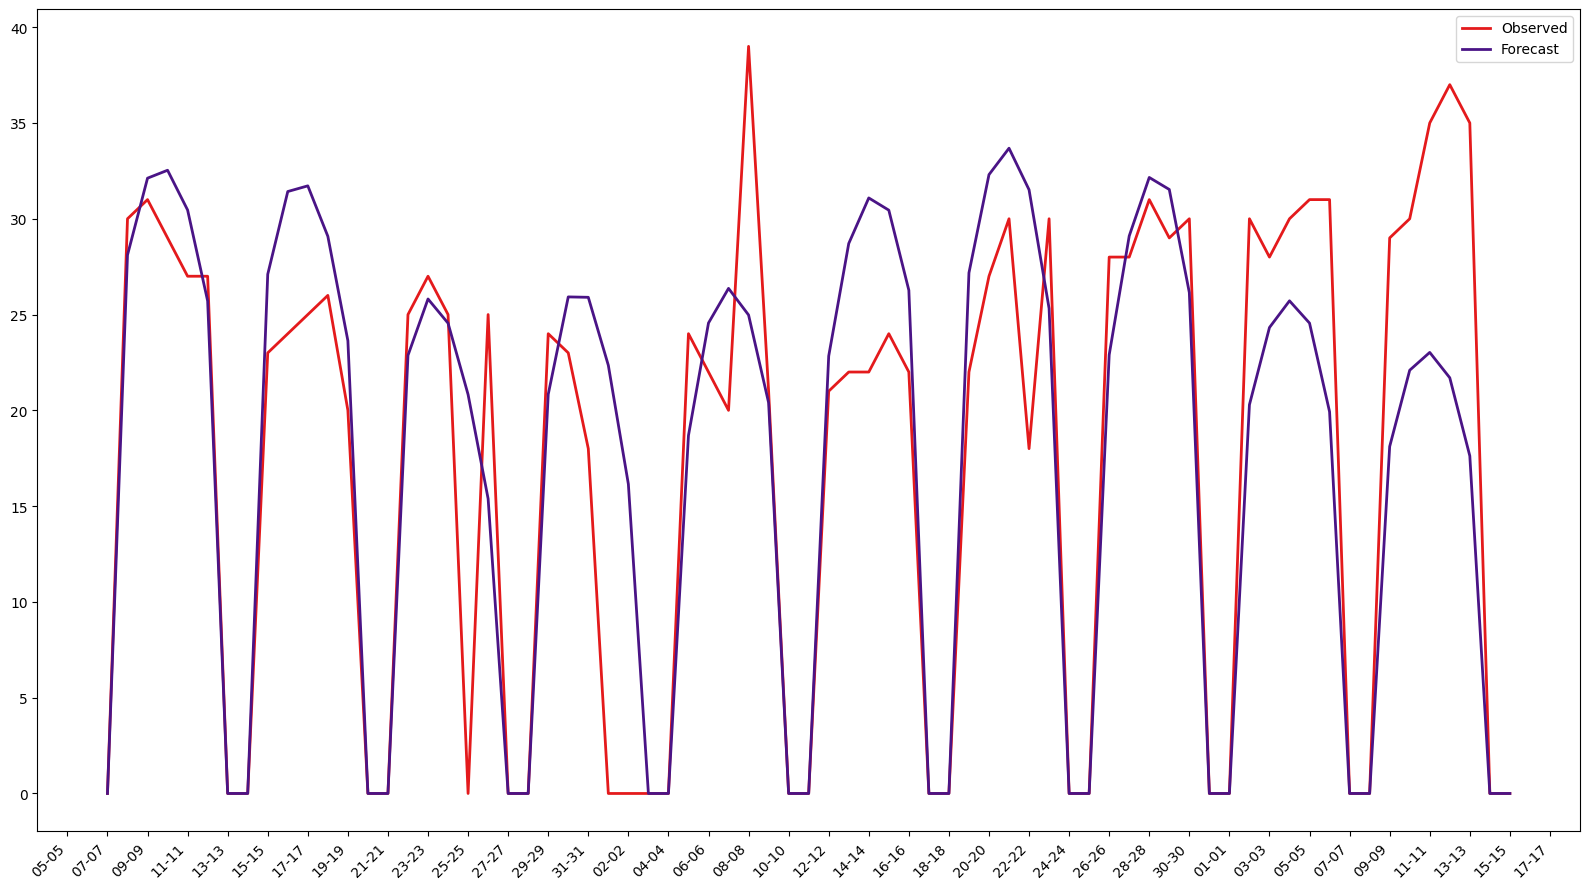

In [32]:
fig, ax = plt.subplots(figsize=(16,9))

ax.plot(eval_train_test2.iloc[(ntrain+1):]['ds'], eval_train_test2.iloc[(ntrain+1):]['y'],
       color = "#e41a1c",
        linewidth = 2,
        label = "Observed")
ax.plot(eval_train_test2.iloc[(ntrain+1):]['ds'],eval_train_test2.iloc[(ntrain+1):]['yhat'],
       color = "#4a1486",
        linewidth = 2,
        label = "Forecast")

ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%d'))

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.legend()                                                  
plt.show()                                                  

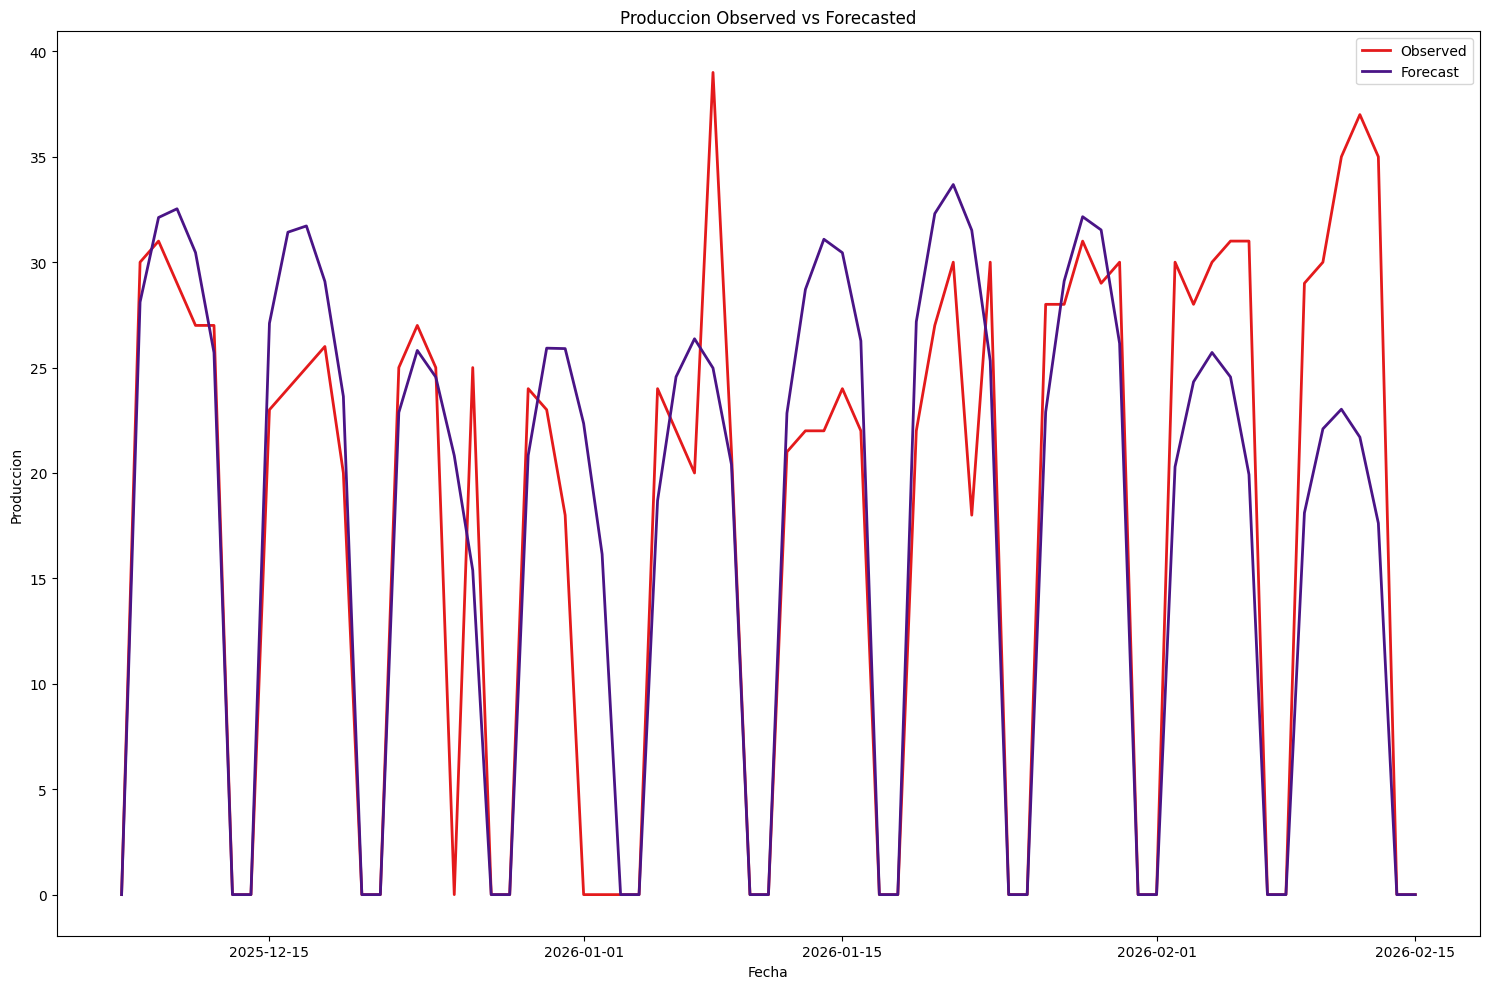

In [33]:
plt.figure(figsize=(15,10))
plt.plot(eval_train_test2.iloc[(ntrain+1):]['ds'],eval_train_test2.iloc[(ntrain+1):]['y'],
        color = "#e41a1c",
        linewidth = 2,
        label = "Observed")
plt.plot(eval_train_test2.iloc[(ntrain+1):]['ds'],eval_train_test2.iloc[(ntrain+1):]['yhat'],
        color = "#4a1486",
        linewidth = 2,
        label = "Forecast")
plt.xlabel("Fecha")
plt.ylabel("Produccion")
plt.title("Produccion Observed vs Forecasted")
plt.legend()
plt.tight_layout()
plt.show()





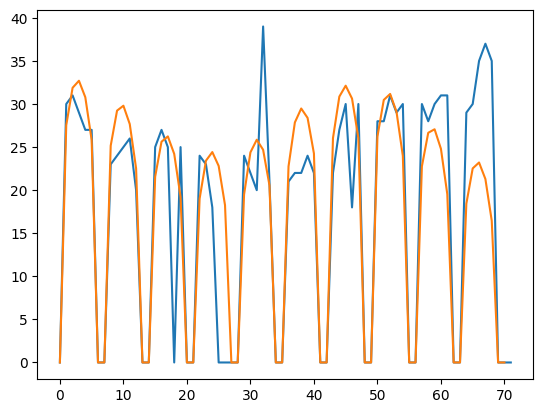

In [34]:
plt.plot(list(validation['y']))
plt.plot(list(forecast.loc[(ntrain+1):,'yhat']))
plt.show()


# Agregar holidays

In [35]:

holidays_train = train[train['tipo_dia'] == 'festivo']['ds']
holidays = pd.DataFrame(
    {'ds': holidays_train
    }
)
holidays['holiday'] = 'holiday'
print(holidays.head(5))
print(holidays.tail(5))
print(holidays.columns)



            ds  holiday
80  2022-05-23  holiday
332 2022-07-25  holiday
404 2022-08-12  holiday
641 2022-10-10  holiday
736 2022-11-03  holiday
             ds  holiday
7404 2025-08-11  holiday
7876 2025-10-09  holiday
7884 2025-10-10  holiday
8076 2025-11-03  holiday
8084 2025-11-04  holiday
Index(['ds', 'holiday'], dtype='object')


In [36]:
m3 = Prophet(holidays = holidays)
m3.fit(train)
future3 = m3.make_future_dataframe(periods=nvalidation)
forecast3 = m3.predict(future3)
forecast3[cols] = forecast3[cols].clip(lower = 0)
print(future3.columns)
print(forecast3.columns)
print(df.columns)


17:17:56.160 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

Index(['ds'], dtype='object')
Index(['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper',
       'additive_terms', 'additive_terms_lower', 'additive_terms_upper',
       'holiday', 'holiday_lower', 'holiday_upper', 'holidays',
       'holidays_lower', 'holidays_upper', 'weekly', 'weekly_lower',
       'weekly_upper', 'yearly', 'yearly_lower', 'yearly_upper',
       'multiplicative_terms', 'multiplicative_terms_lower',
       'multiplicative_terms_upper', 'yhat'],
      dtype='object')
Index(['ds', 'equipo', 'y', 'capacidad', 'tipo_dia', 'novedad', 'weekend'], dtype='object')


In [37]:
## Evaluating forecast with holidays

# Eval train and validation
size_forecast3 = forecast3.shape[0]
forecast3['ds'] = pd.to_datetime(forecast3['ds'])
df['ds'] = pd.to_datetime(df['ds'])

eval_train_test3 = forecast3[['ds','yhat']].merge(df[['ds','y']],
                                                     on = 'ds',how = 'left')


#eval_train_test = forecast[['ds','yhat']].merge(df[['ds','y']].iloc[:size_forecast],
#                                                     on = 'ds',how = 'inner')
print("--Train and Validation sets--")
print(f"min date: {eval_train_test3['ds'].min()}")
print(f"max date: {eval_train_test3['ds'].max()}")

print(eval_train_test3.tail(5))

--Train and Validation sets--
min date: 2022-05-03 00:00:00
max date: 2026-02-15 00:00:00
             ds       yhat   y
1380 2026-02-11  26.692904  35
1381 2026-02-12  25.463946  37
1382 2026-02-13  24.385373  35
1383 2026-02-14   0.000000   0
1384 2026-02-15   0.000000   0


In [38]:
eval_train_test3['se'] = (eval_train_test3['yhat'] - eval_train_test3['y']) ** 2 
print(eval_train_test3)

             ds       yhat   y          se
0    2022-05-03  57.901857  59    1.205919
1    2022-05-04  58.264768  64   32.892889
2    2022-05-05  56.928695  63   36.860743
3    2022-05-06  55.715784  55    0.512346
4    2022-05-07  10.815014   0  116.964523
...         ...        ...  ..         ...
1380 2026-02-11  26.692904  35   69.007844
1381 2026-02-12  25.463946  37  133.080553
1382 2026-02-13  24.385373  35  112.670297
1383 2026-02-14   0.000000   0    0.000000
1384 2026-02-15   0.000000   0    0.000000

[1385 rows x 4 columns]


In [39]:
print("--Evaluate validation set --")
print("--HALCYON--\n")

print(f"SE = {eval_train_test3['se'].iloc[(train_period+1):].sum()}" )
print(f"MSE ={eval_train_test3['se'].iloc[(train_period+1):].mean()} ")
print(f"RMSE = {(eval_train_test3['se'].iloc[(train_period+1):].mean())**0.5}")

--Evaluate validation set --
--HALCYON--

SE = 4703.876845547592
MSE =66.25178655700834 
RMSE = 8.139520044634594


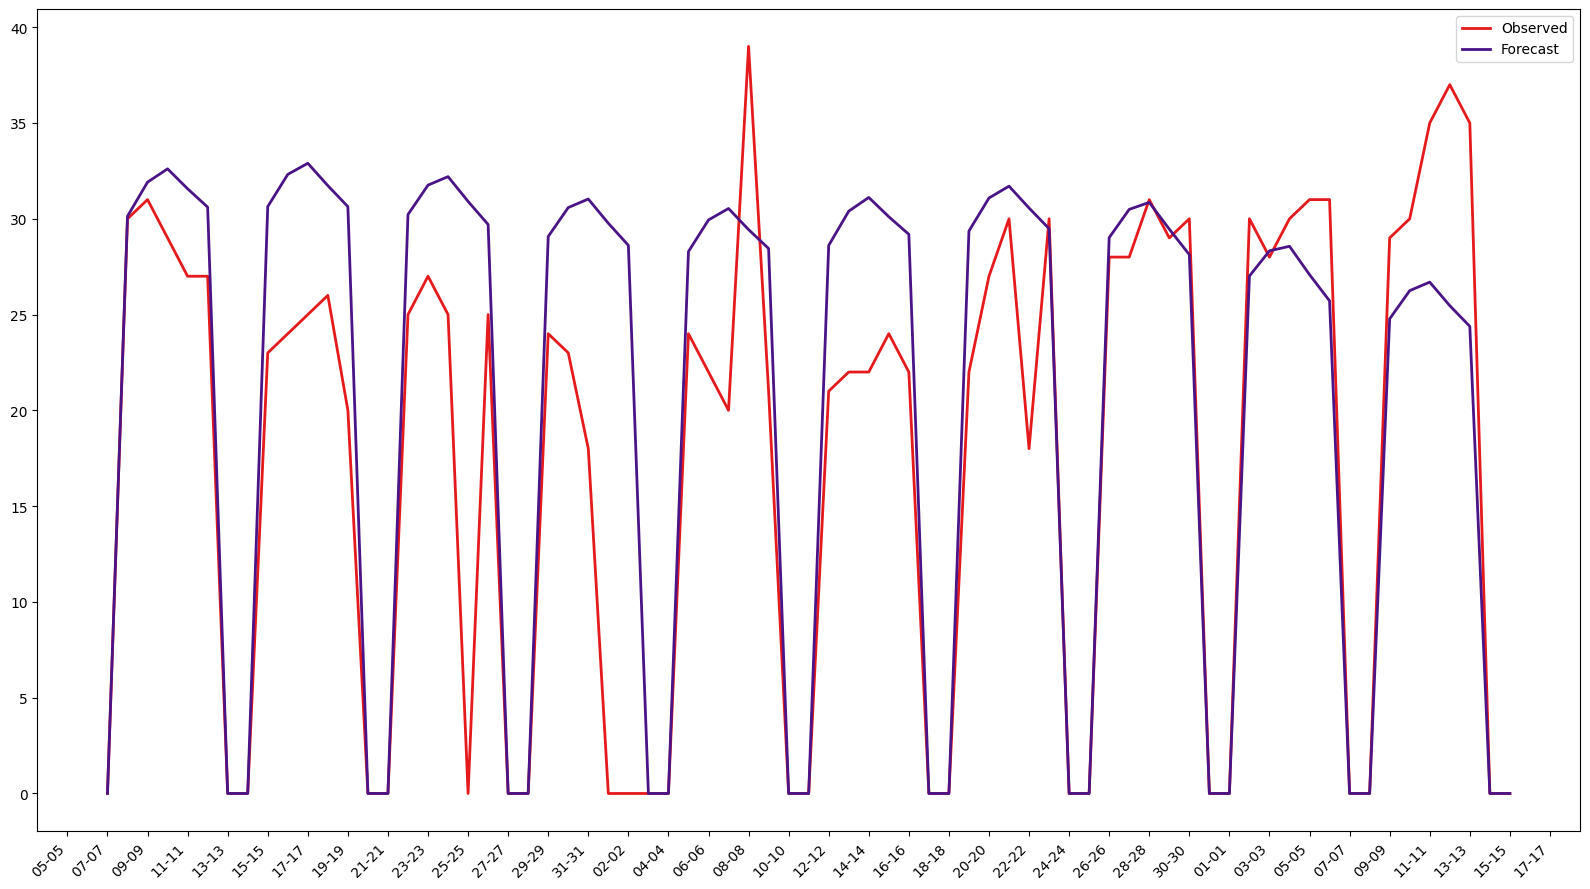

In [40]:
fig3, ax3 = plt.subplots(figsize=(16,9))
ax3.plot(eval_train_test3.iloc[(ntrain+1):]['ds'],eval_train_test3.iloc[(ntrain+1):]['y'],
        color = '#e41a1c',
        linewidth = 2,
        label = "Observed")

ax3.plot(eval_train_test3.iloc[(ntrain+1):]['ds'],eval_train_test3.iloc[(ntrain+1):]['yhat'],
         color = "#4a1486",
         linewidth = 2,
         label = 'Forecast')


ax3.xaxis.set_major_locator(mdates.DayLocator(interval=2))

ax3.xaxis.set_major_formatter(mdates.DateFormatter('%d-%d'))


plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.legend()                                                  
plt.show()                 

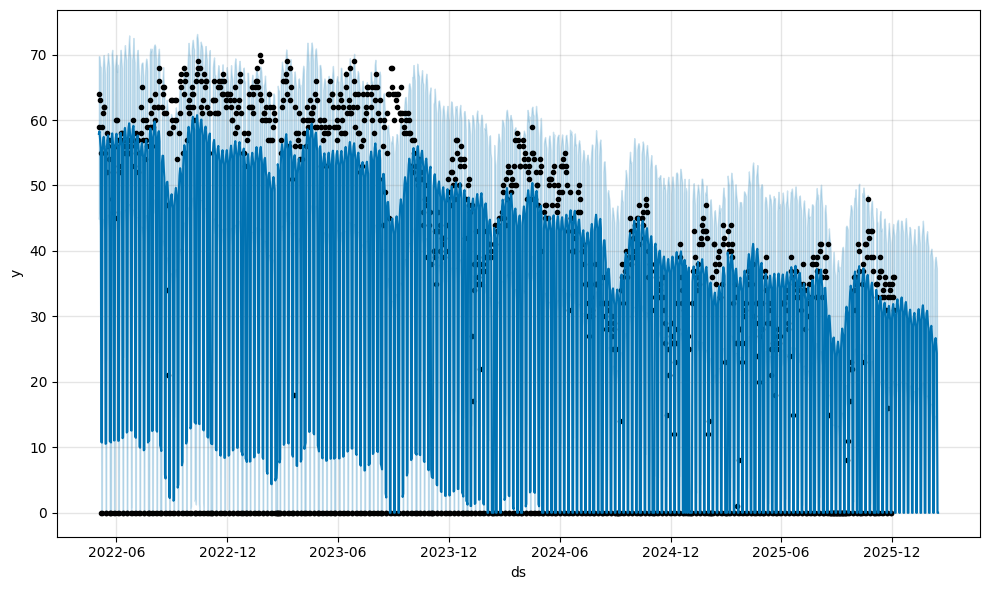

In [41]:
Fig3_1 = m3.plot(forecast3)
plt.show()

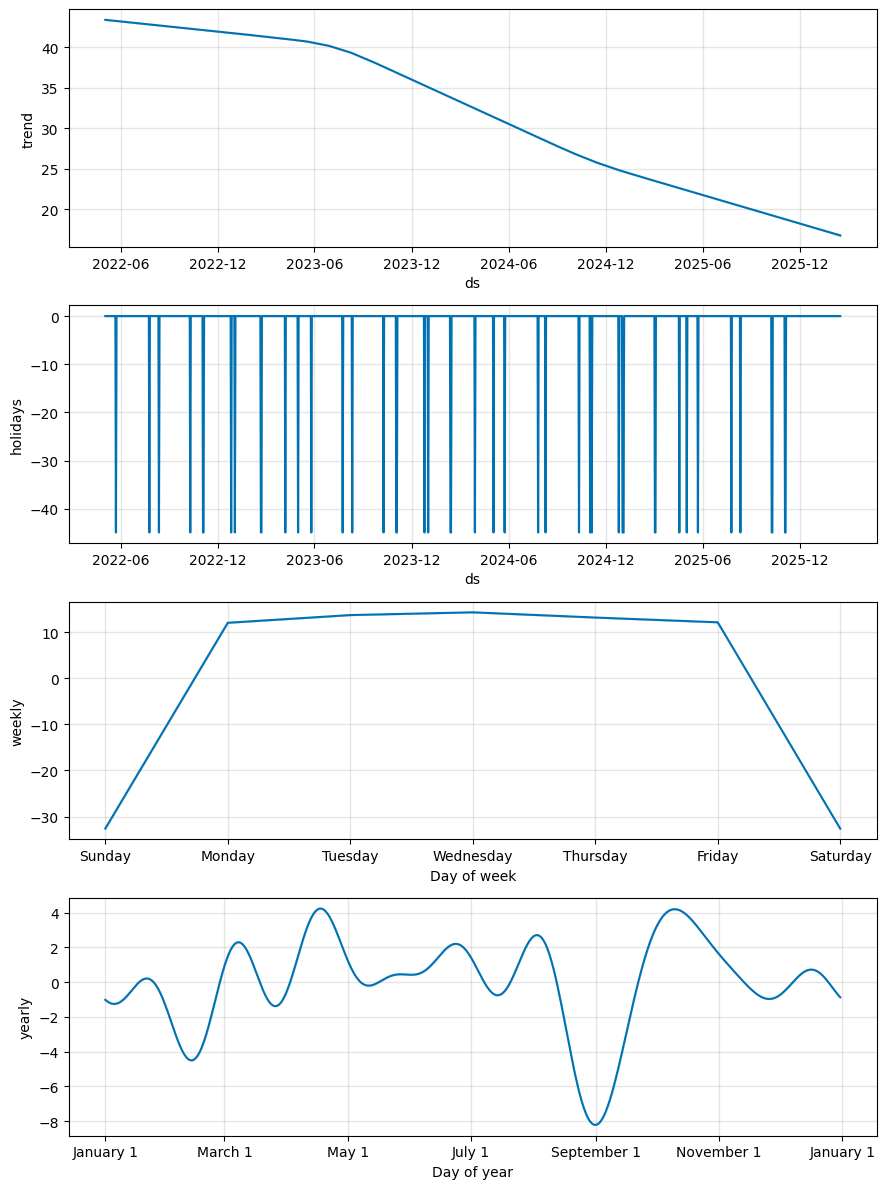

In [42]:
fig3_2 = m3.plot_components(forecast3)
plt.show()

# Agregar variable externa

In [43]:
print(train.columns)

Index(['ds', 'equipo', 'y', 'capacidad', 'tipo_dia', 'novedad', 'weekend'], dtype='object')


In [44]:
m4=Prophet(
    # Seasonal settings
    yearly_seasonality = True, # Enable yearly patterns
    weekly_seasonality = True, # Enable weekly patterns
    daily_seasonality = False, # Disable daily (we have daily data but we want weekly patterns)
    
    # Trend flexibility
    changepoint_prior_scale = 0.05, # lower = less flexible trend changes
    changepoint_range = 0.8, # Proportion of data to consider for changepoints

    # Seasonality strength
    seasonality_prior_scale = 10.0, # Higher = more fleasible seasonality
    seasonality_mode = 'additive', # Additive seasonality (default)

    # Uncertainty intervals
    interval_width = 0.95, # 95% confidence intervals
    mcmc_samples = 0, # use MAP estimation faster than MCMC
    holidays = holidays
)
m4.add_regressor('weekend')
m4.add_seasonality(name = 'monthly', period = 30.5, fourier_order=5)
m4.fit(train)


In [45]:
future4 = m4.make_future_dataframe(periods = nvalidation, freq = 'D')

print(future4.head(5))
print(future4.tail(5))
train_validation = pd.concat([train, validation], ignore_index = True)
print(train_validation.head(5))
print(train_validation.tail(5))
future4 = pd.merge(future4,train_validation[['ds','weekend']], on = 'ds', how = 'left')[['ds','weekend']].fillna(0)
print(future4.columns)
print(future4.head(5))
print(future4.tail(5))


          ds
0 2022-05-03
1 2022-05-04
2 2022-05-05
3 2022-05-06
4 2022-05-07
             ds
1380 2026-02-11
1381 2026-02-12
1382 2026-02-13
1383 2026-02-14
1384 2026-02-15
          ds   equipo   y  capacidad       tipo_dia  novedad  weekend
0 2022-05-03  HALCYON  59         70        laboral  ninguna        0
1 2022-05-04  HALCYON  64         70        laboral  ninguna        0
2 2022-05-05  HALCYON  63         70        laboral  ninguna        0
3 2022-05-06  HALCYON  55         70        laboral  ninguna        0
4 2022-05-07  HALCYON   0          0  fin de semana  ninguna        1
             ds   equipo   y  capacidad       tipo_dia  novedad  weekend
1380 2026-02-12  HALCYON  37         60        laboral  ninguna        0
1381 2026-02-13  HALCYON  35         60        laboral  ninguna        0
1382 2026-02-14  HALCYON   0          0  fin de semana  ninguna        1
1383 2026-02-15  HALCYON   0          0  fin de semana  ninguna        1
1384 2026-02-16  HALCYON   0          0  

In [46]:
forecast4 = m4.predict(future4)
forecast4[cols] = forecast4[cols].clip(lower = 0)

forecast4['ds'] = pd.to_datetime(forecast4['ds'])
train_period = forecast.shape[0] - nvalidation


df['ds'] = pd.to_datetime(df['ds'])

eval_train_test4 = forecast4[['ds','yhat']].merge(df[['ds','y']],
                                                     on = 'ds',how = 'left')


#eval_train_test = forecast[['ds','yhat']].merge(df[['ds','y']].iloc[:size_forecast],
#                                                     on = 'ds',how = 'inner')
print("--Train and Validation sets--")
print(f"min date: {eval_train_test4['ds'].min()}")
print(f"max date: {eval_train_test4['ds'].max()}")

print(eval_train_test4.tail(5))


--Train and Validation sets--
min date: 2022-05-03 00:00:00
max date: 2026-02-15 00:00:00
             ds       yhat   y
1380 2026-02-11  27.078271  35
1381 2026-02-12  25.812831  37
1382 2026-02-13  25.026893  35
1383 2026-02-14   0.000000   0
1384 2026-02-15   0.000000   0


In [47]:
eval_train_test4['se'] = (eval_train_test4['yhat'] - eval_train_test4['y']) ** 2 
print(eval_train_test4)


             ds       yhat   y          se
0    2022-05-03  58.658101  59    0.116895
1    2022-05-04  58.615832  64   28.989260
2    2022-05-05  56.769786  63   38.815563
3    2022-05-06  55.331118  55    0.109639
4    2022-05-07  10.663854   0  113.717776
...         ...        ...  ..         ...
1380 2026-02-11  27.078271  35   62.753797
1381 2026-02-12  25.812831  37  125.152756
1382 2026-02-13  25.026893  35   99.462867
1383 2026-02-14   0.000000   0    0.000000
1384 2026-02-15   0.000000   0    0.000000

[1385 rows x 4 columns]


In [48]:
print("--Evaluate validation set --")
print("--HALCYON--\n")

print(f"SE = {eval_train_test4['se'].iloc[(train_period+1):].sum()}" )
print(f"MSE ={eval_train_test4['se'].iloc[(train_period+1):].mean()} ")
print(f"RMSE = {(eval_train_test4['se'].iloc[(train_period+1):].mean())**0.5}")


--Evaluate validation set --
--HALCYON--

SE = 4770.532531925878
MSE =67.19059904120955 
RMSE = 8.196987192939217


In [49]:
print(r2_score(list(eval_train_test4['y'].iloc[(ntrain+1):]), list(eval_train_test4['yhat'].iloc[(ntrain+1):])))

0.6146440861498776


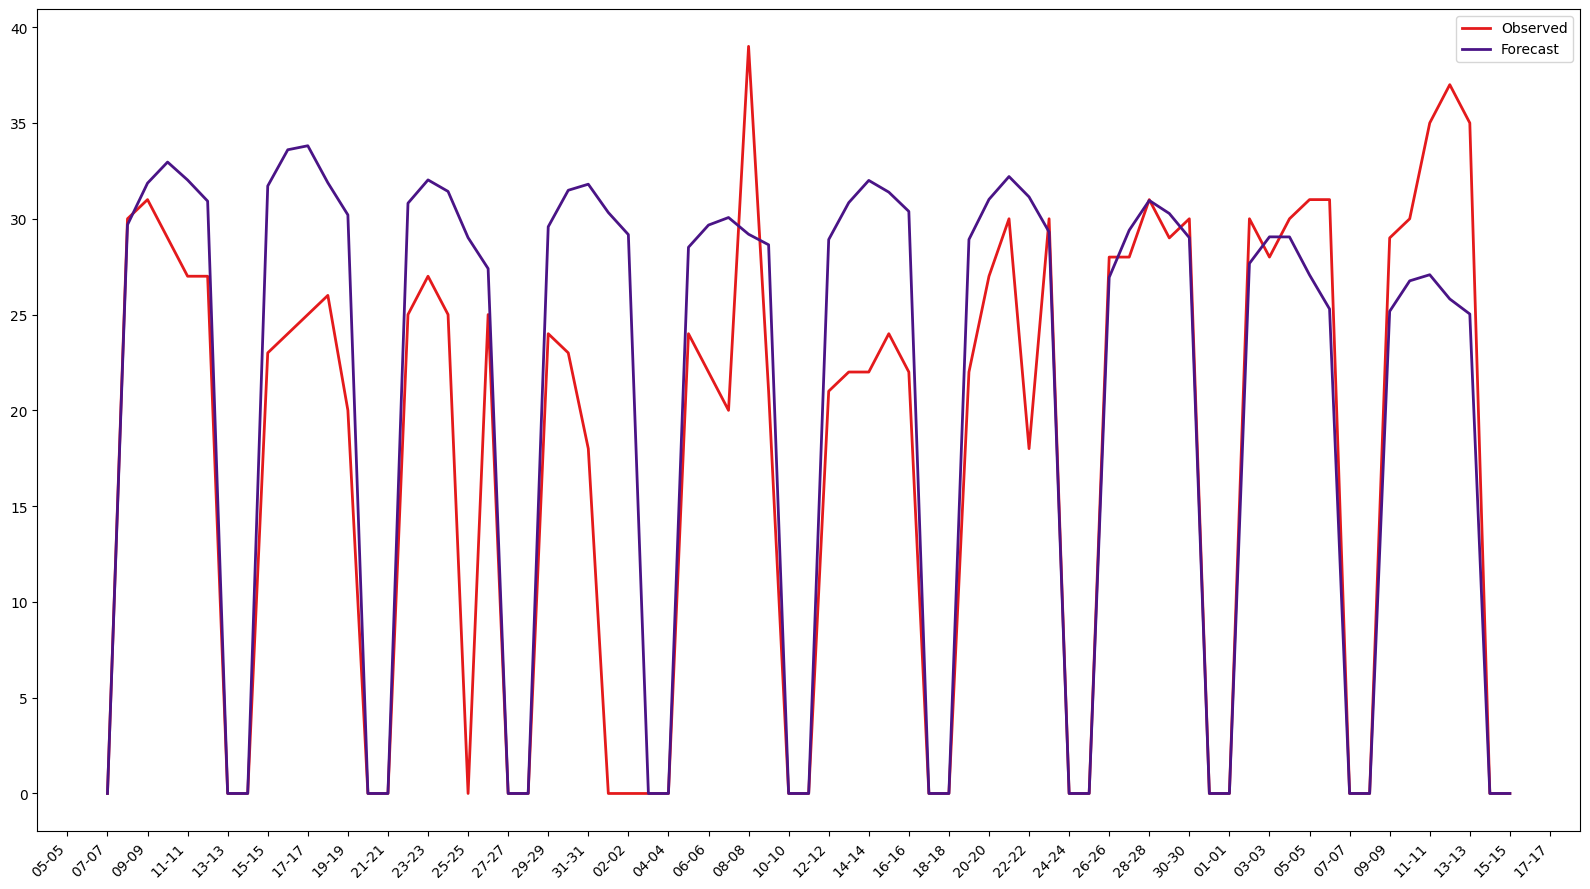

In [50]:
fig4,ax4 = plt.subplots(figsize=(16,9))
ax4.plot(eval_train_test4.iloc[(ntrain+1):]['ds'], eval_train_test4.iloc[(ntrain+1):]['y'],
        color = '#e41a1c',
        linewidth = 2,
        label = 'Observed')

ax4.plot(eval_train_test4.iloc[(ntrain+1):]['ds'], eval_train_test4.iloc[(ntrain+1):]['yhat'],
        color = '#4a1486',
        linewidth = 2,
        label = 'Forecast')

ax4.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax4.xaxis.set_major_formatter(mdates.DateFormatter('%d-%d'))

plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()
plt.legend()
plt.show()


## Bottom up forecasting HALCYON3

In [51]:
df = df_produccion[df_produccion['equipo']=="HALCYON3"]
df['ds'] = pd.to_datetime(df['ds'])

split = int(len(df)*0.9)
print(split)
train = df.iloc[:split]
test_aux = df.iloc[(split+1):]
split1 = int(len(test_aux)*0.5)

validation = test_aux.iloc[:split1]
test = test_aux.iloc[(split1+1):]

ntrain = train.shape[0]
nvalidation = validation.shape[0]
ntest = test.shape[0]

print("=====Training======")
print(f"Observations in training set: {ntrain}")
print(f"min date: {train['ds'].min()}")
print(f"max date: {train['ds'].max()}")

print("=====Validation======")
print(f"Observations in test set: {nvalidation}")
print(f"min date: {validation['ds'].min()}")
print(f"max date: {validation['ds'].max()}")

print("=====Test=====")
print(f"Observations in test set: {ntest}")
print(f"min date: {test['ds'].min()}")
print(f"max date: {test['ds'].max()}")



858
=====Training======
Observations in training set: 858
min date: 2023-09-20 00:00:00
max date: 2026-01-24 00:00:00
=====Validation======
Observations in test set: 47
min date: 2026-01-26 00:00:00
max date: 2026-03-13 00:00:00
=====Test=====
Observations in test set: 47
min date: 2026-03-15 00:00:00
max date: 2026-04-30 00:00:00


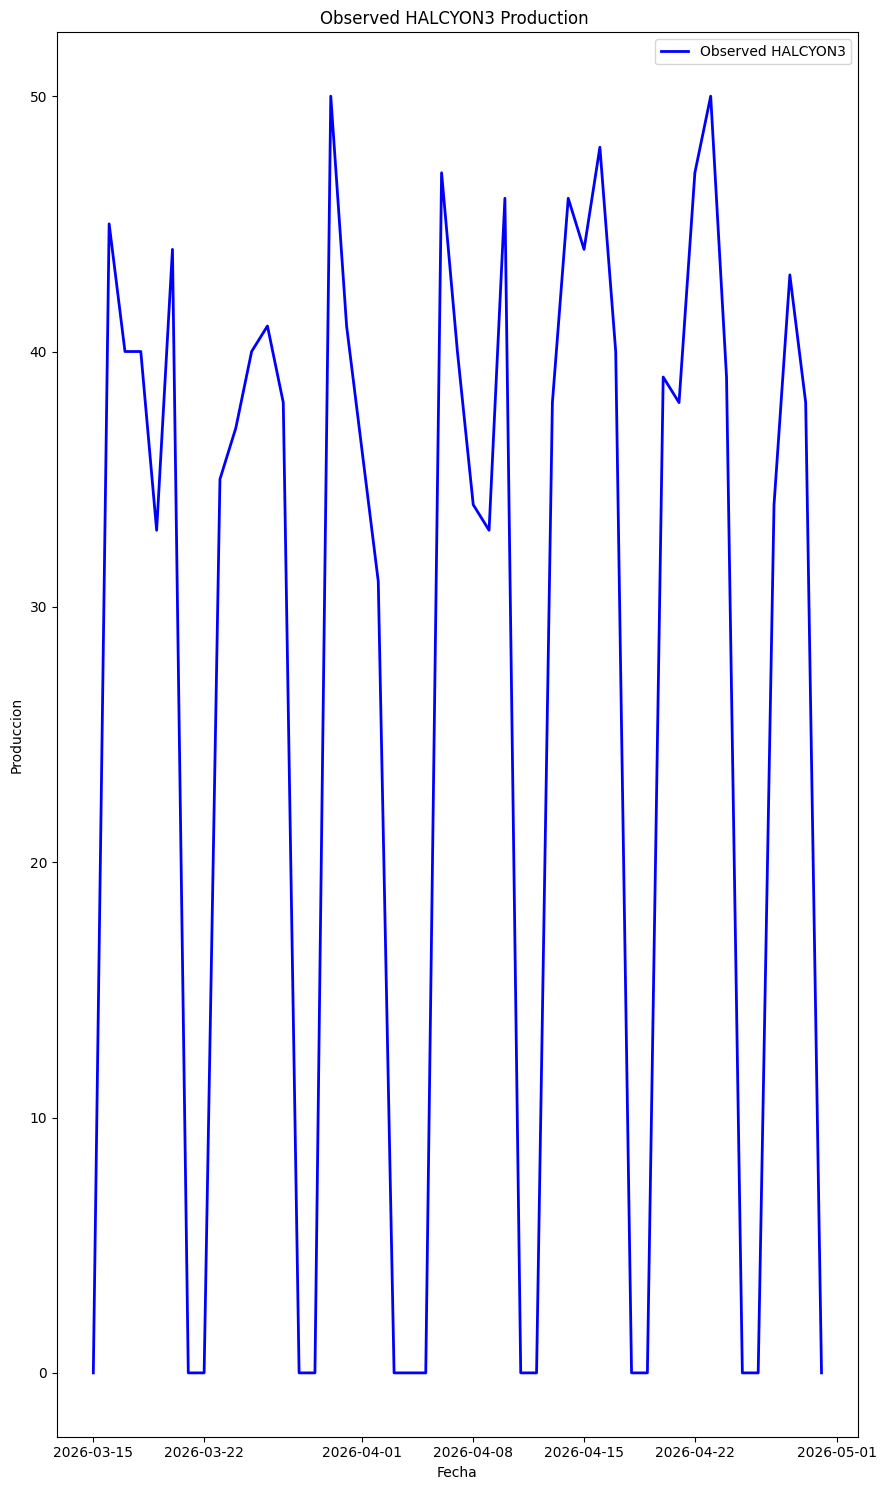

In [52]:
plt.figure(figsize=(9,15))
plt.plot(test['ds'],test['y'],
        color = "blue",
        linewidth = 2,
        label = "Observed HALCYON3")
plt.xlabel("Fecha")
plt.ylabel("Produccion")
plt.title("Observed HALCYON3 Production ")
plt.legend()
plt.tight_layout()
plt.show()



In [53]:
# Initialize and fit Prophet model
m5 = Prophet(
    
    # Seasonal settings
    yearly_seasonality = True, # Enable yearly patterns
    weekly_seasonality = True, # Enable weekly patterns
    daily_seasonality = False, # Disable daily (we have daily data but we want weekly patterns)
    
    # Trend flexibility
    changepoint_prior_scale = 0.05, # lower = less flexible trend changes
    changepoint_range = 0.8, # Proportion of data to consider for changepoints

    # Seasonality strength
    seasonality_prior_scale = 10.0, # Higher = more fleasible seasonality
    seasonality_mode = 'additive', # Additive seasonality (default)

    # Uncertainty intervals
    interval_width = 0.95, # 95% confidence intervals
    mcmc_samples = 0, # use MAP estimation faster than MCMC
    holidays = holidays
)
m5.add_regressor('weekend')
m5.add_seasonality(name = 'monthly', period = 30.5, fourier_order=5)
m5.fit(train)


In [54]:
future5 = m5.make_future_dataframe(periods = nvalidation, freq = 'D')

train_validation = pd.concat([train, validation], ignore_index = True)
print(train_validation.head(5))
print(train_validation.tail(5))
future5 = pd.merge(future5,train_validation[['ds','weekend']], on = 'ds', how = 'left')[['ds','weekend']].fillna(0)
train_period = forecast5.shape[0] - nvalidation


          ds    equipo  y  capacidad       tipo_dia  novedad  weekend
0 2023-09-20  HALCYON3  3         37        laboral  ninguna        0
1 2023-09-21  HALCYON3  5         37        laboral  ninguna        0
2 2023-09-22  HALCYON3  8         37        laboral  ninguna        0
3 2023-09-23  HALCYON3  0          0  fin de semana  ninguna        1
4 2023-09-24  HALCYON3  0          0  fin de semana  ninguna        1
            ds    equipo   y  capacidad tipo_dia             novedad  weekend
900 2026-03-09  HALCYON3  25         65  laboral  Control de Calidad        0
901 2026-03-10  HALCYON3  35         65  laboral             ninguna        0
902 2026-03-11  HALCYON3  39         65  laboral             ninguna        0
903 2026-03-12  HALCYON3  34         65  laboral             ninguna        0
904 2026-03-13  HALCYON3  47         65  laboral             ninguna        0


NameError: name 'forecast5' is not defined

In [ ]:
forecast5 = m5.predict(future5)
forecast5[cols] = forecast5[cols].clip(lower = 0)

forecast5['ds'] = pd.to_datetime(forecast5['ds'])
df['ds'] = pd.to_datetime(df['ds'])

eval_train_test5 = forecast5[['ds','yhat']].merge(df[['ds','y']],
                                                     on = 'ds',how = 'left')


#eval_train_test = forecast[['ds','yhat']].merge(df[['ds','y']].iloc[:size_forecast],
#                                                     on = 'ds',how = 'inner')
print("--Train and Validation sets--")
print(f"min date: {eval_train_test5['ds'].min()}")
print(f"max date: {eval_train_test5['ds'].max()}")



In [ ]:
eval_train_test5['se'] = (eval_train_test5['yhat'] - eval_train_test5['y']) ** 2 
print(eval_train_test5)

In [ ]:
plt.figure(figsize = (9,15))
plt.plot(eval_train_test5.iloc[ntrain:]['ds'], eval_train_test5.iloc[ntrain:]['y'], 
         color = "blue", linewidth = 2, label = "Observed HALCYON3")
plt.plot(eval_train_test5.iloc[ntrain:]['ds'], eval_train_test5.iloc[ntrain:]['yhat'], 
         color = "red", linewidth = 2, label = "Predicted HALCYON3")
plt.xlabel("Date")
plt.ylabel("Services")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("--Evaluate validation set --")
print("--HALCYON3--\n")

print(f"SE = {eval_train_test4['se'].iloc[(train_period+1):].sum()}" )
print(f"MSE ={eval_train_test4['se'].iloc[(train_period+1):].mean()} ")
print(f"RMSE = {(eval_train_test4['se'].iloc[(train_period+1):].mean())**0.5}")


## Bottom up forecasting HALCYON4

In [ ]:
df = df_produccion[df_produccion['equipo']=="HALCYON4"]
df['ds'] = pd.to_datetime(df['ds'])

split = int(len(df)*0.9)
print(split)
train = df.iloc[:split]
test_aux = df.iloc[(split+1):]
split1 = int(len(test_aux)*0.5)

validation = test_aux.iloc[:split1]
test = test_aux.iloc[(split1+1):]

ntrain = train.shape[0]
nvalidation = validation.shape[0]
ntest = test.shape[0]

print("=====Training======")
print(f"Observations in training set: {ntrain}")
print(f"min date: {train['ds'].min()}")
print(f"max date: {train['ds'].max()}")

print("=====Validation======")
print(f"Observations in test set: {nvalidation}")
print(f"min date: {validation['ds'].min()}")
print(f"max date: {validation['ds'].max()}")

print("=====Test=====")
print(f"Observations in test set: {ntest}")
print(f"min date: {test['ds'].min()}")
print(f"max date: {test['ds'].max()}")



In [ ]:
plt.figure(figsize=(9,15))
plt.plot(test['ds'],test['y'],
        color = "blue",
        linewidth = 2,
        label = "Observed HALCYON3")
plt.xlabel("Dates")
plt.ylabel("Production")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Initialize and fit Prophet model
mh4 = Prophet(
    
    # Seasonal settings
    yearly_seasonality = True, # Enable yearly patterns
    weekly_seasonality = True, # Enable weekly patterns
    daily_seasonality = False, # Disable daily (we have daily data but we want weekly patterns)
    
    # Trend flexibility
    changepoint_prior_scale = 0.05, # lower = less flexible trend changes
    changepoint_range = 0.8, # Proportion of data to consider for changepoints

    # Seasonality strength
    seasonality_prior_scale = 10.0, # Higher = more fleasible seasonality
    seasonality_mode = 'additive', # Additive seasonality (default)

    # Uncertainty intervals
    interval_width = 0.95, # 95% confidence intervals
    mcmc_samples = 0, # use MAP estimation faster than MCMC
    holidays = holidays
)
mh4.add_regressor('weekend')
mh4.add_seasonality(name = 'monthly', period = 30.5, fourier_order=5)
mh4.fit(train)

In [ ]:
futureh4 = mh4.make_future_dataframe(periods = nvalidation, freq = 'D')

train_validation = pd.concat([train, validation], ignore_index = True)
print(train_validation.head(5))
print(train_validation.tail(5))
futureh4 = pd.merge(futureh4,train_validation[['ds','weekend']], on = 'ds', how = 'left')[['ds','weekend']].fillna(0)


In [ ]:
forecasth4 = mh4.predict(futureh4)
forecasth4[cols] = forecasth4[cols].clip(lower = 0)
train_period = forecasth4.shape[0] - nvalidation

forecasth4['ds'] = pd.to_datetime(forecasth4['ds'])
df['ds'] = pd.to_datetime(df['ds'])

eval_train_testh4 = forecasth4[['ds','yhat']].merge(df[['ds','y']],
                                                     on = 'ds',how = 'left')

eval_train_testh4['se'] = (eval_train_testh4['yhat'] - eval_train_testh4['y']) ** 2 
print(eval_train_testh4)



In [ ]:
plt.figure(figsize = (9,15))
plt.plot(eval_train_testh4.iloc[ntrain:]['ds'], eval_train_testh4.iloc[ntrain:]['y'] , color = "blue", linewidth = 2, label = "observed")
plt.plot(eval_train_testh4.iloc[ntrain:]['ds'], eval_train_testh4.iloc[ntrain:]['yhat'] , color = "red", linewidth = 2, label = "predicted")
plt.xlabel("Date")
plt.ylabel("Production")
plt.title("HALCYON4 Observed Production")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
print("--Evaluate validation set --")
print("--HALCYON4--\n")

print(f"SE = {eval_train_testh4['se'].iloc[(train_period+1):].sum()}" )
print(f"MSE ={eval_train_testh4['se'].iloc[(train_period+1):].mean()} ")
print(f"RMSE = {(eval_train_testh4['se'].iloc[(train_period+1):].mean())**0.5}")